## Dataset Overview & Schema

- **Source Used for Analysis:** Local validation JSON (`lvis_v1_val.json`) from LVIS v1.0 paired with COCO image URLs (`http://images.cocodataset.org/...`)
- **Where to Get Full Dataset Later:** Official LVIS download page: [https://www.lvisdataset.org/dataset](https://www.lvisdataset.org/dataset) (annotations) and [https://cocodataset.org/#download](https://cocodataset.org/#download) (images)
- **Full Dataset Size:** ~21 GB total (~180 MB compressed JSON annotations + ~20 GB shared COCO 2017 train/val images)
- **Classes:** 1,203 categories with long-tail frequency tiers (`r`=rare, `c`=common, `f`=frequent)

### 1. `images` Table
Metadata for each image in the dataset:

| Column | Type | Description |
| :--- | :--- | :--- |
| `id` / `image_id` | `int` | Unique image identifier (matches COCO image ID). |
| `date_captured` | `str` | Timestamp of image capture. |
| `license` | `int` | Image license identifier. |
| `height`, `width` | `int` | Image dimensions in pixels. |
| `flickr_url` | `str` | Original Flickr URL. |
| `coco_url` | `str` | Download URL for the image on COCO dataset host. |
| `neg_category_ids` | `list[int]` | Category IDs confirmed to be absent from this image. |
| `not_exhaustive_category_ids` | `list[int]` | Categories that were not exhaustively annotated in this image. |

### 2. `annotations` Table
Per-instance segmentation and bounding box annotations:

| Column | Type | Description |
| :--- | :--- | :--- |
| `id` | `int` | Unique annotation identifier. |
| `image_id` | `int` | ID of the image containing this instance. |
| `category_id` | `int` | Class identifier (matches `categories.id`, 1 to 1203). |
| `bbox` | `list[float]` | Bounding box in COCO format: `[x, y, width, height]`. |
| `area` | `float` | Segmentation mask area in pixels. |
| `segmentation` | `list` / `dict` | Polygon vertices (`[[x1, y1, x2, y2, ...]]`) or RLE dict (`counts`, `size`). |

### 3. `categories` Table
Vocabulary definition for all 1,203 object classes:

| Column | Type | Description |
| :--- | :--- | :--- |
| `id` | `int` | Category identifier ($1$ to $1203$). |
| `name` | `str` | Primary category name (e.g., `'airplane'`, `'alarm_clock'`). |
| `synonyms` | `list[str]` | List of synonyms for the category. |
| `def` | `str` | Dictionary definition of the concept. |
| `synset` | `str` | WordNet synset identifier (e.g., `'airplane.n.01'`). |
| `frequency` | `str` | Frequency tier: `'r'` (rare, <10 images), `'c'` (common, 10–100), `'f'` (frequent, >100). |
| `image_count` | `int` | Number of images containing this category. |
| `instance_count` | `int` | Total number of annotated instances. |

### 4. Processed `annotations_df` Table
After joining `images` metadata and extracting polygon coordinates:

| Column | Type | Description |
| :--- | :--- | :--- |
| `image_id` | `int` | Image identifier (sorted, indexed). |
| `category_id` | `int` | Category ID. |
| `bbox` | `list[float]` | `[x, y, width, height]` coordinates. |
| `area` | `float` | Mask area in square pixels. |
| `segmentation` | `list` / `dict` | Original polygon coordinate list or RLE object. |
| `height`, `width` | `int` | Image dimensions in pixels. |
| `coco_url` | `str` | Image download URL used for visual rendering. |
| `x`, `y` | `list[float]` | Extracted x and y boundary vertex coordinates for the primary polygon. |


### 1. Load LVIS JSON and create DataFrames


In [93]:
import json
import pandas as pd

# Load LVIS v1 validation annotations
with open("lvis_v1_val.json", "r", encoding="utf-8") as f:
    lvis_data = json.load(f)

# Inspect top-level dictionary keys
print(lvis_data.keys())

# Convert core tables into DataFrames
images_df = pd.DataFrame(lvis_data["images"])
annotations_df = pd.DataFrame(lvis_data["annotations"])
categories_df = pd.DataFrame(lvis_data["categories"])

images_df


dict_keys(['info', 'categories', 'annotations', 'images', 'licenses'])


,date_captured,neg_category_ids,id,license,height,width,flickr_url,coco_url,not_exhaustive_category_ids
0,2013-11-14 17:02:52,"[279, 899, 127, 180, 1136, 725, 663]",397133,4,427,640,http://farm7.staticflickr.com/6116/6255196340_...,http://images.cocodataset.org/val2017/00000039...,"[914, 801, 566, 139, 1021]"
1,2013-11-14 20:55:31,"[1002, 434, 924, 928, 951, 378, 1012, 867, 108...",37777,1,230,352,http://farm9.staticflickr.com/8429/7839199426_...,http://images.cocodataset.org/val2017/00000003...,"[181, 45]"
2,2013-11-14 22:32:02,"[194, 899, 248, 587, 201, 838, 1112, 1061, 337...",252219,4,428,640,http://farm4.staticflickr.com/3446/3232237447_...,http://images.cocodataset.org/val2017/00000025...,[948]
3,2013-11-14 23:11:37,"[149, 713, 654, 1112, 753, 579]",87038,1,480,640,http://farm8.staticflickr.com/7355/8825114508_...,http://images.cocodataset.org/val2017/00000008...,"[94, 1043]"
4,2013-11-14 23:16:55,"[22, 369, 176, 653, 89, 11, 753, 474]",174482,6,388,640,http://farm8.staticflickr.com/7020/6478877255_...,http://images.cocodataset.org/val2017/00000017...,[1112]
...,...,...,...,...,...,...,...,...,...
19804,2013-11-24 13:20:54,"[1014, 1148, 857, 80, 660, 142, 13]",125910,4,640,480,http://farm8.staticflickr.com/7392/9308795953_...,http://images.cocodataset.org/train2017/000000...,[1122]
19805,2013-11-24 20:54:28,"[782, 1126, 608, 857, 1053, 486, 380, 992, 270]",342307,3,375,500,http://farm4.staticflickr.com/3076/3160532038_...,http://images.cocodataset.org/train2017/000000...,[]
19806,2013-11-24 21:59:45,"[21, 857, 1008, 57, 800, 531, 15, 1202, 1120]",432062,1,433,640,http://farm4.staticflickr.com/3114/2305083105_...,http://images.cocodataset.org/train2017/000000...,[]
19807,2013-11-24 22:39:24,"[335, 1085, 672, 190, 489]",347405,3,427,640,http://farm6.staticflickr.com/5511/9585778258_...,http://images.cocodataset.org/train2017/000000...,[]


### 2. Inspect annotations table


In [94]:
# Display annotations table (bounding boxes, segmentations, category IDs)
annotations_df


,area,id,segmentation,image_id,bbox,category_id
0,73297.48,1,"[[270.75, 598.57, 261.98, 598.57, 247.84, 598....",446522,"[83.08, 219.88, 301.69, 420.12]",232
1,70204.06,2,"[[0.0, 626.21, 90.53, 629.18, 97.12, 611.7, 10...",446522,"[0.0, 0.0, 132.41, 629.18]",421
2,289.97,3,"[[238.16, 386.84, 240.61, 387.95, 245.96, 385....",76261,"[238.16, 340.87, 66.44, 47.08]",99
3,238.39,4,"[[392.16, 220.43, 395.79, 219.28, 400.38, 216....",76261,"[368.84, 181.21, 51.42, 59.88]",99
4,100734.18,5,"[[23.83, 156.28, 0.0, 162.64, 0.0, 427.0, 166....",454750,"[0.0, 14.7, 413.66, 412.3]",1202
...,...,...,...,...,...,...
244702,4.72,244703,"[[209.04, 181.65, 208.15, 182.21, 207.92, 182....",358717,"[207.92, 181.65, 2.35, 2.8]",125
244703,15.41,244704,"[[72.17, 253.4, 74.78, 254.09, 75.99, 252.7, 7...",358717,"[71.65, 249.5, 4.6, 4.59]",125
244704,2.75,244705,"[[24.1, 257.12, 24.62, 257.47, 25.15, 257.64, ...",358717,"[24.1, 256.0, 2.17, 1.64]",125
244705,5.38,244706,"[[215.52, 186.01, 214.45, 185.69, 213.38, 185....",358717,"[212.74, 185.69, 2.86, 2.46]",125


### 3. Inspect categories table


In [95]:
# Display categories table (1,203 classes with synsets and frequency tiers)
categories_df


,image_count,synonyms,def,id,synset,name,frequency,instance_count
0,8,"[aerosol_can, spray_can]",a dispenser that holds a substance under pressure,1,aerosol.n.02,aerosol_can,c,11
1,65,[air_conditioner],a machine that keeps air cool and dry,2,air_conditioner.n.01,air_conditioner,f,146
2,349,"[airplane, aeroplane]",an aircraft that has a fixed wing and is power...,3,airplane.n.01,airplane,f,619
3,25,[alarm_clock],a clock that wakes a sleeper at some preset time,4,alarm_clock.n.01,alarm_clock,f,60
4,14,"[alcohol, alcoholic_beverage]",a liquor or brew containing alcohol as the act...,5,alcohol.n.01,alcohol,c,149
...,...,...,...,...,...,...,...,...
1198,0,[yacht],an expensive vessel propelled by sail or power...,1199,yacht.n.01,yacht,c,0
1199,7,"[yogurt, yoghurt, yoghourt]",a custard-like food made from curdled milk,1200,yogurt.n.01,yogurt,c,9
1200,3,[yoke_(animal_equipment)],gear joining two animals at the neck; NOT egg ...,1201,yoke.n.07,yoke_(animal_equipment),c,4
1201,325,[zebra],any of several fleet black-and-white striped A...,1202,zebra.n.01,zebra,f,1037


### 4. Filter images with annotations


In [96]:
# Keep only images that have at least one annotated object
images_df = images_df[images_df["id"].isin(annotations_df["image_id"])]


### 5. Merge image metadata into annotations


In [97]:
# Rename 'id' to 'image_id' and index for join
images_df = images_df.rename(columns={"id": "image_id"}, errors="ignore").set_index("image_id")

# Merge image metadata (dimensions, URLs) into annotations table
annotations_df = annotations_df.join(images_df, on="image_id", how="left").drop(columns=["id"], errors="ignore").sort_values(by=["image_id"])
annotations_df.head()


,area,segmentation,image_id,bbox,category_id,date_captured,neg_category_ids,license,height,width,flickr_url,coco_url,not_exhaustive_category_ids
194764,1792.41,"[[477.47, 47.04, 478.84, 44.64, 482.96, 43.09,...",9,"[464.19, 40.93, 59.94, 45.43]",735,2013-11-19 20:40:11,"[99, 50, 1051, 418, 332, 1136, 231, 248]",3,480,640,http://farm5.staticflickr.com/4026/4622125393_...,http://images.cocodataset.org/train2017/000000...,[735]
194767,1487.67,"[[192.39, 188.04, 197.76, 190.73, 202.78, 192....",9,"[184.5, 159.36, 56.46, 34.06]",7,2013-11-19 20:40:11,"[99, 50, 1051, 418, 332, 1136, 231, 248]",3,480,640,http://farm5.staticflickr.com/4026/4622125393_...,http://images.cocodataset.org/train2017/000000...,[735]
194766,1339.85,"[[258.34, 226.83, 253.78, 217.97, 252.92, 214....",9,"[252.06, 183.26, 48.37, 43.57]",7,2013-11-19 20:40:11,"[99, 50, 1051, 418, 332, 1136, 231, 248]",3,480,640,http://farm5.staticflickr.com/4026/4622125393_...,http://images.cocodataset.org/train2017/000000...,[735]
194765,2320.48,"[[388.17, 85.35, 381.31, 78.96, 376.2, 73.85, ...",9,"[373.16, 39.52, 75.53, 45.83]",735,2013-11-19 20:40:11,"[99, 50, 1051, 418, 332, 1136, 231, 248]",3,480,640,http://farm5.staticflickr.com/4026/4622125393_...,http://images.cocodataset.org/train2017/000000...,[735]
194768,1650.70,"[[156.06, 109.66, 157.19, 117.96, 159.91, 127....",9,"[154.72, 91.06, 42.04, 63.2]",7,2013-11-19 20:40:11,"[99, 50, 1051, 418, 332, 1136, 231, 248]",3,480,640,http://farm5.staticflickr.com/4026/4622125393_...,http://images.cocodataset.org/train2017/000000...,[735]


### 6. Extract polygon X and Y coordinates


In [106]:
def extract_xy_polygons(seg):
    """Extract separate X and Y coordinate lists from polygon segmentation."""
    # RLE segmentations are dicts, not polygon lists
    if not isinstance(seg, list) or len(seg) == 0:
        return None, None

    xs_per_poly = []
    ys_per_poly = []
    for poly in seg:
        if isinstance(poly, list) and len(poly) >= 6:
            xs_per_poly.append(poly[0::2])  # Even indices are X coordinates
            ys_per_poly.append(poly[1::2])  # Odd indices are Y coordinates

    if not xs_per_poly:
        return None, None
    return xs_per_poly[0], ys_per_poly[0]


# Extract X and Y vertex lists for the primary polygon
xy_pairs = annotations_df["segmentation"].apply(extract_xy_polygons)
annotations_df["x"] = [pair[0] for pair in xy_pairs]
annotations_df["y"] = [pair[1] for pair in xy_pairs]

annotations_df


,area,segmentation,image_id,bbox,category_id,date_captured,neg_category_ids,license,height,width,flickr_url,coco_url,not_exhaustive_category_ids,x,y
194764,1792.41,"[[477.47, 47.04, 478.84, 44.64, 482.96, 43.09,...",9,"[464.19, 40.93, 59.94, 45.43]",735,2013-11-19 20:40:11,"[99, 50, 1051, 418, 332, 1136, 231, 248]",3,480,640,http://farm5.staticflickr.com/4026/4622125393_...,http://images.cocodataset.org/train2017/000000...,[735],"[477.47, 478.84, 482.96, 484.67, 487.42, 491.5...","[47.04, 44.64, 43.09, 42.24, 41.38, 41.38, 41...."
194767,1487.67,"[[192.39, 188.04, 197.76, 190.73, 202.78, 192....",9,"[184.5, 159.36, 56.46, 34.06]",7,2013-11-19 20:40:11,"[99, 50, 1051, 418, 332, 1136, 231, 248]",3,480,640,http://farm5.staticflickr.com/4026/4622125393_...,http://images.cocodataset.org/train2017/000000...,[735],"[192.39, 197.76, 202.78, 209.41, 216.22, 222.5...","[188.04, 190.73, 192.7, 193.42, 193.06, 192.34..."
194766,1339.85,"[[258.34, 226.83, 253.78, 217.97, 252.92, 214....",9,"[252.06, 183.26, 48.37, 43.57]",7,2013-11-19 20:40:11,"[99, 50, 1051, 418, 332, 1136, 231, 248]",3,480,640,http://farm5.staticflickr.com/4026/4622125393_...,http://images.cocodataset.org/train2017/000000...,[735],"[258.34, 253.78, 252.92, 252.06, 252.31, 255.6...","[226.83, 217.97, 214.65, 206.77, 201.48, 193.8..."
194765,2320.48,"[[388.17, 85.35, 381.31, 78.96, 376.2, 73.85, ...",9,"[373.16, 39.52, 75.53, 45.83]",735,2013-11-19 20:40:11,"[99, 50, 1051, 418, 332, 1136, 231, 248]",3,480,640,http://farm5.staticflickr.com/4026/4622125393_...,http://images.cocodataset.org/train2017/000000...,[735],"[388.17, 381.31, 376.2, 373.16, 376.2, 379.39,...","[85.35, 78.96, 73.85, 70.82, 63.15, 57.88, 51...."
194768,1650.70,"[[156.06, 109.66, 157.19, 117.96, 159.91, 127....",9,"[154.72, 91.06, 42.04, 63.2]",7,2013-11-19 20:40:11,"[99, 50, 1051, 418, 332, 1136, 231, 248]",3,480,640,http://farm5.staticflickr.com/4026/4622125393_...,http://images.cocodataset.org/train2017/000000...,[735],"[156.06, 157.19, 159.91, 166.39, 176.06, 184.3...","[109.66, 117.96, 127.59, 140.09, 148.41, 152.9..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101450,3.13,"[[111.37, 122.17, 112.1, 121.15, 114.89, 121.4...",581813,"[111.37, 121.15, 3.52, 1.32]",943,2013-11-19 01:33:09,"[236, 1102, 1127, 56, 496, 1182, 874]",4,480,640,http://farm3.staticflickr.com/2870/9177451561_...,http://images.cocodataset.org/train2017/000000...,[],"[111.37, 112.1, 114.89, 114.3, 111.37]","[122.17, 121.15, 121.44, 122.47, 122.17]"
101451,13.03,"[[158.53, 124.71, 159.39, 123.34, 160.25, 123....",581813,"[158.53, 123.17, 5.83, 3.77]",943,2013-11-19 01:33:09,"[236, 1102, 1127, 56, 496, 1182, 874]",4,480,640,http://farm3.staticflickr.com/2870/9177451561_...,http://images.cocodataset.org/train2017/000000...,[],"[158.53, 159.39, 160.25, 161.45, 162.13, 162.8...","[124.71, 123.34, 123.17, 123.51, 123.68, 123.6..."
101447,2.62,"[[114.19, 122.75, 115.68, 123.25, 116.67, 123....",581813,"[114.19, 121.76, 2.48, 1.49]",943,2013-11-19 01:33:09,"[236, 1102, 1127, 56, 496, 1182, 874]",4,480,640,http://farm3.staticflickr.com/2870/9177451561_...,http://images.cocodataset.org/train2017/000000...,[],"[114.19, 115.68, 116.67, 116.18, 115.43, 114.4...","[122.75, 123.25, 123.0, 122.01, 121.76, 121.76..."
101453,4.29,"[[106.77, 124.74, 107.57, 123.81, 108.64, 123....",581813,"[106.77, 123.41, 5.07, 1.46]",943,2013-11-19 01:33:09,"[236, 1102, 1127, 56, 496, 1182, 874]",4,480,640,http://farm3.staticflickr.com/2870/9177451561_...,http://images.cocodataset.org/train2017/000000...,[],"[106.77, 107.57, 108.64, 109.97, 110.78, 111.4...","[124.74, 123.81, 123.81, 123.94, 123.54, 123.4..."


### 7. Select a random image for visualization


In [145]:
import random

# Pick a random image ID from the annotated dataset
unique_ids = list(annotations_df["image_id"].unique())
index = random.choice(unique_ids)


### 8. Mask decoding and visualization helpers


In [146]:
from io import BytesIO
import requests
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw
from pycocotools import mask as mask_utils


def _segmentation_to_mask(seg, height, width):
    """Convert a COCO/LVIS segmentation (polygons or RLE) to a (H, W) bool mask."""
    if seg is None:
        return None

    # Polygon format: list of flat coordinate lists [[x1, y1, x2, y2, ...], ...]
    if isinstance(seg, list):
        canvas = Image.new("L", (width, height), 0)
        draw = ImageDraw.Draw(canvas)
        has_valid_poly = False

        for poly in seg:
            if isinstance(poly, list) and len(poly) >= 6:
                pts = [
                    (float(poly[i]), float(poly[i + 1]))
                    for i in range(0, len(poly) - 1, 2)
                ]
                draw.polygon(pts, outline=1, fill=1)
                has_valid_poly = True

        return np.array(canvas, dtype=bool) if has_valid_poly else None

    # RLE format: dict with "counts" and "size"
    if isinstance(seg, dict):
        rle = mask_utils.frPyObjects(seg, height, width)
        if isinstance(rle, list):
            rle = mask_utils.merge(rle)
        decoded = mask_utils.decode(rle)
        if decoded.ndim == 3:
            decoded = np.any(decoded, axis=2)
        return decoded.astype(bool)

    return None


def show_all_masks_for_image(
    image_id=None,
    annotations_df=None,
    xs=None,
    ys=None,
    polygons=None,
    alpha=0.45,
    linewidth=2,
    figsize=(8, 6),
    title=None,
):
    """Download image and overlay segmentation masks and polygon boundaries."""
    response = requests.get(
        annotations_df[annotations_df["image_id"] == image_id]["coco_url"].iloc[0],
        timeout=15,
    )
    response.raise_for_status()

    image = Image.open(BytesIO(response.content)).convert("RGB")
    img_np = np.array(image)
    if img_np.ndim == 2:
        img_np = np.stack([img_np] * 3, axis=-1)

    h, w = img_np.shape[:2]
    instance_masks = []
    outline_polys = []

    # 1. Collect all annotations for this image_id
    if image_id is not None and annotations_df is not None:
        if hasattr(annotations_df, "empty"):
            rows = annotations_df[annotations_df["image_id"] == image_id]
            seg_items = rows["segmentation"].tolist() if not rows.empty else []
        else:
            seg_items = [
                ann.get("segmentation")
                for ann in annotations_df
                if ann.get("image_id") == image_id
            ]

        for seg in seg_items:
            m = _segmentation_to_mask(seg, h, w)
            if m is not None and np.any(m):
                instance_masks.append(m)

            if isinstance(seg, list):
                for poly in seg:
                    if isinstance(poly, list) and len(poly) >= 6:
                        outline_polys.append(np.column_stack([poly[0::2], poly[1::2]]))

    # 2. Optional direct polygon / (xs, ys) input
    if polygons is not None:
        poly_list = (
            [polygons]
            if (len(polygons) > 0 and isinstance(polygons[0], (int, float)))
            else polygons
        )
        m = _segmentation_to_mask(poly_list, h, w)
        if m is not None and np.any(m):
            instance_masks.append(m)
        for poly in poly_list:
            if isinstance(poly, list) and len(poly) >= 6:
                outline_polys.append(np.column_stack([poly[0::2], poly[1::2]]))

    if xs is not None and ys is not None:
        if len(xs) != len(ys):
            raise ValueError("xs and ys must have the same length.")
        if len(xs) >= 3:
            pts = np.column_stack([xs, ys])
            outline_polys.append(pts)
            flat = [coord for pair in zip(xs, ys) for coord in pair]
            m = _segmentation_to_mask([flat], h, w)
            if m is not None and np.any(m):
                instance_masks.append(m)

    # Generate distinct RGB colors for each item
    cmap = plt.get_cmap("tab20")
    overlay = img_np.astype(np.float32)

    for idx, mask in enumerate(instance_masks):
        rgb = (np.array(cmap(idx % 20)[:3]) * 255).astype(np.float32)
        overlay[mask] = (1.0 - alpha) * overlay[mask] + alpha * rgb

    overlay = np.clip(overlay, 0, 255).astype(np.uint8)

    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(overlay)

    if linewidth > 0:
        for idx, pts in enumerate(outline_polys):
            edge_rgb = cmap(idx % 20)[:3]
            patch = plt.Polygon(
                pts,
                closed=True,
                fill=False,
                edgecolor=edge_rgb,
                linewidth=linewidth,
            )
            ax.add_patch(patch)

    ax.set_title(title or f"Image {image_id} — {len(instance_masks)} masked item(s)")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()


### 9. Render masks on selected image


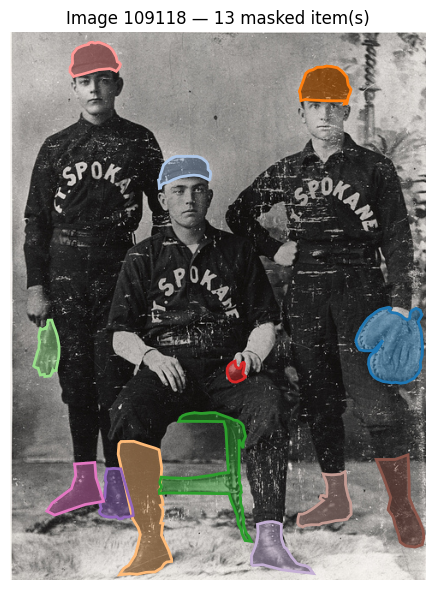

In [147]:
# Render instance masks on the selected image
show_all_masks_for_image(
    image_id=index,
    annotations_df=annotations_df,
    alpha=0.45,
)
